Call: {'price': np.float64(7.1280646692617395), 'delta': np.float64(0.5024132586078932), 'gamma': np.float64(0.01994674906534299), 'vega': np.float64(39.893498130685984), 'theta': np.float64(-5.282747648814426), 'rho': np.float64(43.113261191527585)}
Put:  {'price': np.float64(9.024845691855106), 'delta': np.float64(-0.4975867413921068), 'gamma': np.float64(0.01994674906534299), 'vega': np.float64(39.893498130685984), 'theta': np.float64(-2.225844218136625), 'rho': np.float64(-58.78351983106578)}
Parity (C-P, S-K*e^-rT, holds?): (np.float64(-1.8967810225933661), np.float64(-1.896781022593359), np.True_)
Parity holds for 1000 random cases: True


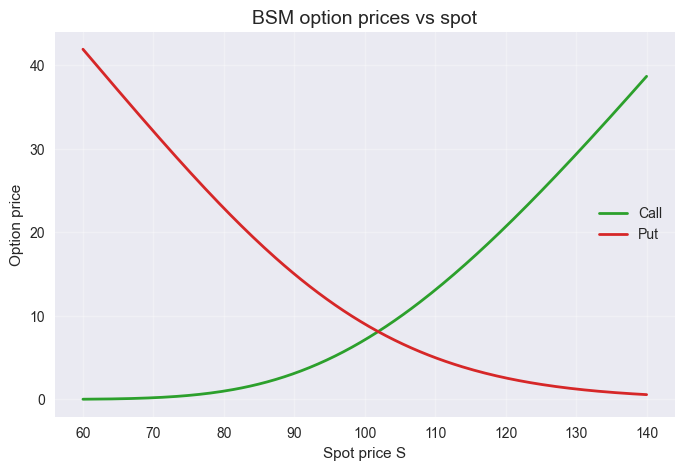

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm


# ---------- a) Customizable plotter ----------
def plot_lines(x, ys, labels=None, title="", xlabel="", ylabel="",
               figsize=(8, 5), colors=None, linestyles=None, linewidth=2,
               grid=True, legend=True, style="seaborn-v0_8", save_path=None):
    """Plot one or several curves with customizable layout."""
    try:
        plt.style.use(style)
    except OSError:
        pass  # fall back to the default style
    fig, ax = plt.subplots(figsize=figsize)
    for i, y in enumerate(ys):
        ax.plot(x, y,
                label=labels[i] if labels else None,
                color=colors[i] if colors else None,
                linestyle=linestyles[i] if linestyles else "-",
                linewidth=linewidth)
    ax.set_title(title, fontsize=14)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    if grid:
        ax.grid(True, alpha=0.3)
    if legend and labels:
        ax.legend()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


# ---------- b) Call option with greeks ----------
def _d1_d2(S, K, T, r, sigma):
    d1 = (np.log(S / K) + (r + 0.5 * sigma ** 2) * T) / (sigma * np.sqrt(T))
    return d1, d1 - sigma * np.sqrt(T)


def bsm_call(S, K, T, r, sigma, greeks=False):
    d1, d2 = _d1_d2(S, K, T, r, sigma)
    price = S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    if not greeks:
        return price
    return {
        "price": price,
        "delta": norm.cdf(d1),
        "gamma": norm.pdf(d1) / (S * sigma * np.sqrt(T)),
        "vega": S * norm.pdf(d1) * np.sqrt(T),
        "theta": -S * norm.pdf(d1) * sigma / (2 * np.sqrt(T))
                 - r * K * np.exp(-r * T) * norm.cdf(d2),
        "rho": K * T * np.exp(-r * T) * norm.cdf(d2),
    }


# ---------- c) European put option ----------
def bsm_put(S, K, T, r, sigma, greeks=False):
    d1, d2 = _d1_d2(S, K, T, r, sigma)
    price = K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)
    if not greeks:
        return price
    return {
        "price": price,
        "delta": norm.cdf(d1) - 1,
        "gamma": norm.pdf(d1) / (S * sigma * np.sqrt(T)),
        "vega": S * norm.pdf(d1) * np.sqrt(T),
        "theta": -S * norm.pdf(d1) * sigma / (2 * np.sqrt(T))
                 + r * K * np.exp(-r * T) * norm.cdf(-d2),
        "rho": -K * T * np.exp(-r * T) * norm.cdf(-d2),
    }


# ---------- d) Put-call parity: C - P = S - K*exp(-rT) ----------
def check_parity(S, K, T, r, sigma, tol=1e-8):
    lhs = bsm_call(S, K, T, r, sigma) - bsm_put(S, K, T, r, sigma)
    rhs = S - K * np.exp(-r * T)
    return lhs, rhs, abs(lhs - rhs) < tol


# ---------- Demo ----------
S, K, T, r, sigma = 100, 105, 1.0, 0.03, 0.2
print("Call:", bsm_call(S, K, T, r, sigma, greeks=True))
print("Put: ", bsm_put(S, K, T, r, sigma, greeks=True))
print("Parity (C-P, S-K*e^-rT, holds?):", check_parity(S, K, T, r, sigma))

# Check parity on many random parameter sets
rng = np.random.default_rng(0)
all_ok = all(
    check_parity(rng.uniform(50, 150), rng.uniform(50, 150),
                 rng.uniform(0.1, 3), rng.uniform(0, 0.08),
                 rng.uniform(0.05, 0.6))[2]
    for _ in range(1000)
)
print("Parity holds for 1000 random cases:", all_ok)

# Plot: call and put prices against the stock price
spots = np.linspace(60, 140, 200)
plot_lines(spots,
           [bsm_call(spots, K, T, r, sigma), bsm_put(spots, K, T, r, sigma)],
           labels=["Call", "Put"], colors=["tab:green", "tab:red"],
           title="BSM option prices vs spot", xlabel="Spot price S",
           ylabel="Option price")